# Trained Expected Periodogram Explorer

This notebook loads the neural network trained in `nn_spectral_example.py` to directly predict the tapered expected periodogram (on a log10 scale) of a Matern covariance model. The Matern smoothness is controlled by $\nu$ ($\nu=0.5$ is the Exponential model, $\nu=1.5$ is Matern32, $\nu=2.5$ is Matern52). Two sliders let you sweep the range parameter $\rho$ and the smoothness $\nu$ (between 0.5 and 2.5) and see the corresponding predicted $\log_{10}(\text{EP})$.

In [1]:
%matplotlib widget
import torch
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

from debiased_spatial_whittle.backend import BackendManager
BackendManager.set_backend("torch")
BackendManager.device = "cpu"

from debiased_spatial_whittle.grids.base import RectangularGrid
from debiased_spatial_whittle.models.univariate import (
    ExponentialModel,
    Matern32Model,
    Matern52Model,
)

# Matern smoothness nu -> model class. Only these discrete nu values have a
# dedicated covariance model class available for sampling / true EP.
NU_MODELS = {
    0.5: ExponentialModel,
    1.5: Matern32Model,
    2.5: Matern52Model,
}


def make_model(rho, nu, sigma=1.0):
    """Build the Matern covariance model matching the nearest discrete nu."""
    nearest = min(NU_MODELS, key=lambda k: abs(k - float(nu)))
    model_cls = NU_MODELS[nearest]
    return model_cls(rho=torch.tensor(rho), sigma=torch.tensor(sigma))


In [2]:
# Load the saved model
checkpoint = torch.load("nn_spectral_ep_model.pt", weights_only=False)
arch = checkpoint["architecture"]
meta = checkpoint["metadata"]

# Rebuild the MLP with the same architecture
layers = []
dims = [arch["in_dim"]] + arch["hidden_dims"] + [arch["out_dim"]]
for i in range(len(dims) - 1):
    layers.append(torch.nn.Linear(dims[i], dims[i + 1], dtype=torch.float64))
    if i < len(dims) - 2:
        layers.append(torch.nn.ReLU())
nn_module = torch.nn.Sequential(*layers)
nn_module.load_state_dict(checkpoint["state_dict"])
nn_module.eval()

# Restore metadata
grid_n = meta["grid_n"]
ndim = meta["ndim"]
sigma_value = meta["sigma_value"]
log_rho_min = meta["log_rho_min"]
log_rho_max = meta["log_rho_max"]
nu_min = meta["nu_min"]
nu_max = meta["nu_max"]
rho_min = np.exp(log_rho_min)
rho_max = np.exp(log_rho_max)

# Build the (2*n1, 2*n2) frequency grid (fold=False)
padded_n = tuple(2 * s for s in grid_n)
freq_1d = [torch.fft.fftfreq(2 * n_i, 1.0) for n_i in grid_n]
freq_mesh = torch.meshgrid(*freq_1d, indexing="ij")
freq_grid = torch.stack(freq_mesh, axis=-1)  # (2*n1, 2*n2, d)
N_freq = int(np.prod(padded_n))
freq_flat = freq_grid.reshape(N_freq, ndim)

def scale_log_rho(log_rho):
    return 2.0 * (log_rho - log_rho_min) / (log_rho_max - log_rho_min) - 1.0

def scale_nu(nu):
    return 2.0 * (nu - nu_min) / (nu_max - nu_min) - 1.0

def _predict_ep_ln(rho, nu):
    """Run the NN on the full frequency grid (chunked); return ln(EP) in FFT order."""
    scaled_rho = scale_log_rho(np.log(rho))
    scaled_nu = scale_nu(nu)
    params = torch.tensor([scaled_rho, scaled_nu], dtype=torch.float64)
    chunk_size = 8192 * 16
    pred_parts = []
    with torch.no_grad():
        for start in range(0, N_freq, chunk_size):
            end = min(start + chunk_size, N_freq)
            param_rows = params.unsqueeze(0).expand(end - start, 2)
            freq_chunk = _mirror_neg_freqs(freq_flat[start:end])
            nn_input = torch.cat([param_rows, freq_chunk], dim=1)
            pred_parts.append(nn_module(nn_input).squeeze(-1))
    return torch.cat(pred_parts).reshape(*padded_n)

def predict_ep_log10(rho, nu):
    """log10(EP) in fftshifted order for given (rho, nu)."""
    pred_ln_ep = _predict_ep_ln(rho, nu)
    return np.fft.fftshift((pred_ln_ep / np.log(10)).numpy())

from debiased_spatial_whittle.inference.tapers import HanningTaper
from debiased_spatial_whittle.inference.nn_ep import _mirror_neg_freqs
from debiased_spatial_whittle.sampling.simulation import SamplerOnRectangularGrid

def predict_residuals(rho, nu):
    """Compute 1 - exp(-P/EP) for a fresh sample. nu is snapped to the nearest
    discrete Matern class ({0.5, 1.5, 2.5}) for sampling, since only those have a
    dedicated covariance model. The EP prediction still uses the continuous nu."""
    grid = RectangularGrid(tuple(grid_n))
    taper = HanningTaper()
    model = make_model(rho, nu, sigma=sigma_value)
    sampler = SamplerOnRectangularGrid(model, grid)
    sample = sampler()
    taper_vals = taper(grid_n)
    tapered = sample.values * taper_vals
    p = torch.abs(torch.fft.fftn(tapered, s=padded_n)) ** 2
    p = p.real / np.prod(grid_n)

    pred_ep = torch.exp(_predict_ep_ln(rho, nu))
    resid = 1.0 - torch.exp(-p / pred_ep)
    return np.fft.fftshift(resid.numpy())

print(f"Model loaded. Grid: {grid_n}, padded: {padded_n}, "
      f"rho range: [{rho_min}, {rho_max}], nu range: [{nu_min}, {nu_max}]")


Model loaded. Grid: (128, 128), padded: (256, 256), rho range: [2.0, 32.0], nu range: [0.5, 2.5]

In [3]:
class EpPlotter:
    def __init__(self):
        # Compute fixed vmin/vmax across the (rho, nu) training domain
        rho_grid = np.exp(np.linspace(log_rho_min, log_rho_max, 10))
        nu_grid = np.linspace(nu_min, nu_max, 5)
        all_ep = [predict_ep_log10(r, n) for r in rho_grid for n in nu_grid]
        self.ep_vmin = min(e.min() for e in all_ep)
        self.ep_vmax = max(e.max() for e in all_ep)

        self.fig, (self.ax, self.ax_resid) = plt.subplots(1, 2, figsize=(12, 5))
        self.im = self.ax.imshow(np.zeros(padded_n), origin="lower", cmap="magma",
                                  vmin=self.ep_vmin, vmax=self.ep_vmax)
        self.ax.set_xticks([])
        self.ax.set_yticks([])
        self.cbar = self.fig.colorbar(self.im, ax=self.ax, label="log10(EP)")

        self.im_resid = self.ax_resid.imshow(np.zeros(padded_n), origin="lower",
                                              cmap="RdBu_r", vmin=0, vmax=1)
        self.ax_resid.set_xticks([])
        self.ax_resid.set_yticks([])
        self.cbar_resid = self.fig.colorbar(self.im_resid, ax=self.ax_resid,
                                             label="1 - exp(-P/EP)")
        self.fig.tight_layout()

    def plot_trained_ep(self, rho, nu):
        """Predict and plot log10(EP) and residuals for a given (rho, nu)."""
        ep_np = predict_ep_log10(rho, nu)
        self.im.set_data(ep_np)
        self.ax.set_title(f"Trained log10(EP), rho={rho:.2f}, nu={nu:.2f}")

        resid_np = predict_residuals(rho, nu)
        self.im_resid.set_data(resid_np)
        self.ax_resid.set_title(f"1 - exp(-P/EP), rho={rho:.2f}, nu={nu:.2f}")

        self.fig.canvas.draw_idle()


interactive(children=(FloatSlider(value=8.0, description='rho', max=32.0, min=2.0), FloatSlider(value=1.5, des…

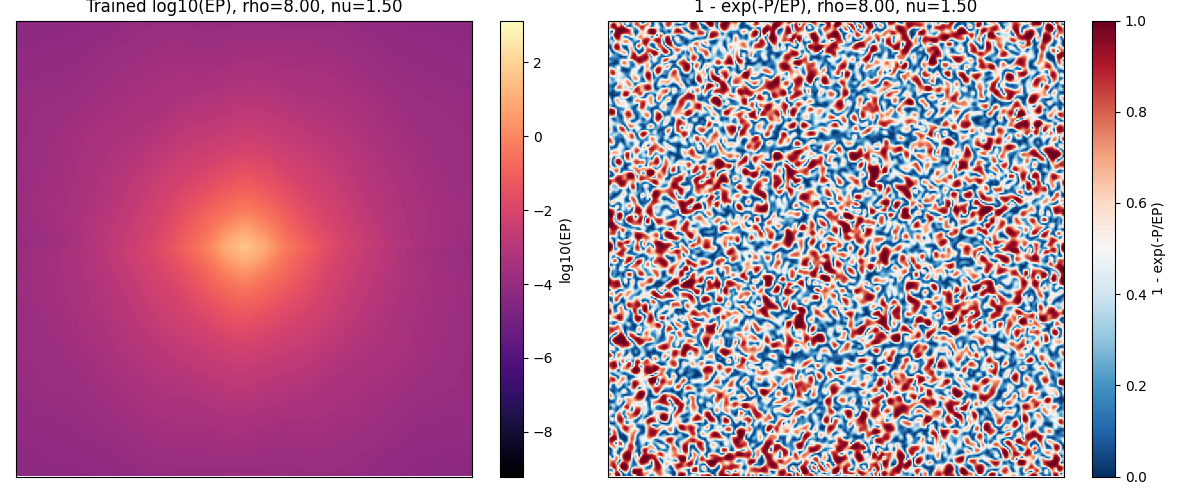

In [4]:
ep_plotter = EpPlotter()
interact(
    ep_plotter.plot_trained_ep,
    rho=FloatSlider(min=rho_min, max=rho_max, step=0.1, value=8.0,
                    description="rho", readout_format=".2f"),
    nu=FloatSlider(min=nu_min, max=nu_max, step=0.05, value=1.5,
                   description="nu", readout_format=".2f"),
);
